<div style="text-align: center; margin-bottom: 25px;">
    <div style="margin-bottom: 20px;">
        <img src="https://upload.wikimedia.org/wikipedia/fr/5/5f/Safran_-_logo_2016.png" style="height: 60px; width: auto; vertical-align: middle; margin: 0 20px;">
    </div>
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Visualisation du BER de DeepBCJR</h1>
    </div>
</div>

## **1. Importation des modules**

In [1]:
import time
import datetime
import math as m
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt

import maxstar as ms
import maxlogmap2 as mp

from keras import models 

## **2. Récupération du modèle**

In [3]:
network = models.load_model("deepbcjr.keras")

network.summary ()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 100, 128)       │        26,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 100, 32)        │        20,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 100, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 100, 1)         │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 143,141 (559.15 KB)

 Trainable params: 47,713 (186.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 95,428 (372.77 KB)

## **3. Définition des paramètres**

In [4]:
batch = 10000
trame = 100
Eb = 1
Code_Rate = 1/2
Ec = Eb*Code_Rate
snr11 = np.linspace (0, 11, 12)
rnn = [0 for k in range (8)]
t = [0.5 * m.erfc (np.sqrt (10**(k/10))) for k in snr11]
turboabs = [0.8, 0.9, 1, 1.1, 1.2, 1.3]
turboord = [0.0015, 0.0009, 0.0004, 0.0001, 0.00003, 0.00001]

LogMap = [0.084883, 0.047444, 0.021736, 0.007406, 0.001827, 0.00031475, 3.48e-05, 2.8e-06]
MaxLogMap = [0.086916, 0.043561, 0.016764, 0.005205, 0.001063, 0.0001617, 1.677e-05, 9.75e-07]

## **4. Monte Carlo**

In [8]:
for i in range (len (rnn)):
    nombre_erreur = 0
    nombre_bits = 0
    
    while nombre_erreur < 2000 and nombre_bits < 5*10**6 :
        
        W = rd.randint (0, 2, (batch, trame, 1))
        Z = np.array ([ms.forme (h) for h in W])
        N0 = 10**(-snr11[i]/10)
        bruit = np.sqrt (N0/2) * np.random.randn(len(W), trame +2, 2)
        X = Z * np.sqrt (Ec)+ bruit
        
        predictions = network.predict (X, verbose = 1)#.reshape (batch, trame+2)
        #predictions = np.array ([mp.maxlogmap (h) for h in X]).reshape ((10000, 102, 1))
        
        nombre_erreur += np.sum(W != (predictions [:, :-2, :]< 0).astype(int))
        nombre_bits += trame*batch

    print(f"Étape {i} : erreurs accumulées = {nombre_erreur}, bits traités = {nombre_bits}, BER = {nombre_erreur/nombre_bits}")
    rnn[i] = nombre_erreur/nombre_bits

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
Étape 0 : erreurs accumulées = 87414, bits traités = 1000000, BER = 0.087414
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Étape 1 : erreurs accumulées = 43949, bits traités = 1000000, BER = 0.043949
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Étape 2 : erreurs accumulées = 17212, bits traités = 1000000, BER = 0.017212
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Étape 3 : erreurs accumulées = 4978, bits traités = 1000000, BER = 0.004978
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Étape 4 : erreurs accumulées = 2024, bits traités = 2000000, BER = 0.001012
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Étape 5 : erreurs accumulées = 804, bits traités = 5000000, BER = 0.0001608
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/

## **5. Visualisation des performances**

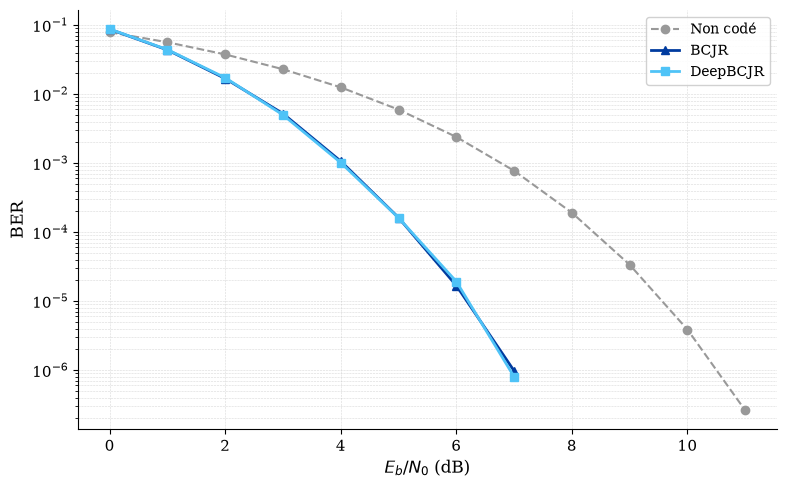

In [70]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,})

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(snr11, t, color='#999999', marker='o', markersize=6, linestyle='--', linewidth=1.5, label='Non codé')
ax.plot(snr11[:8], MaxLogMap, color='#003B9F', marker='^', markersize=6, linestyle='-', linewidth=2, label='BCJR')
ax.plot(snr11[:8], rnn, color='#4FC3F7', marker='s', markersize=6, linestyle='-', linewidth=2, label='DeepBCJR')

ax.set_yscale('log')
ax.set_xlabel('$E_b/N_0$ (dB)', fontsize=12)
ax.set_ylabel('BER', fontsize=12)
ax.grid(True, which='both', linestyle='--', linewidth=0.4, alpha=0.5)
ax.set_axisbelow(True)
ax.legend(fontsize=10, framealpha=0.9, loc='upper right')

plt.tight_layout()
#plt.savefig('BER.png', dpi=300, bbox_inches='tight')
plt.show()

## **6. Calcul de la vitesse de décodage**

#### **6.1. BCJR**

In [57]:
batch = 1000
trame = 100

W = rd.randint (0, 2, (batch, trame, 1))
Z = np.array ([ms.forme (h) for h in W])
N0 = 10**(-2/10)
bruit = np.sqrt (N0/2) * np.random.randn(len(W), trame +2, 2)
X = Z * np.sqrt (Ec)+ bruit

start = time.time ()
predictions = np.array ([mp.maxlogmap (h) for h in X])
end = time.time ()

print(f"Decoding time : {(end - start)*1000/len (X):.3f} ms -----> trame de {X.shape[1]} bits")

Decoding time : 2.112 ms -----> trame de 102 bits


#### **6.2. DeepBCJR**

In [55]:
batch = 1000
trame = 100

W = rd.randint (0, 2, (batch, trame, 1))
Z = np.array ([ms.forme (h) for h in W])
N0 = 10**(-2/10)
bruit = np.sqrt (N0/2) * np.random.randn(len(W), trame +2, 2)
X = Z * np.sqrt (Ec)+ bruit

start = time.time ()
predictions = network.predict (X)
end = time.time ()

print(f"Decoding time : {(end - start)*1000/len (X):.3f} ms -----> trame de {X.shape[1]} bits")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Decoding time : 0.415 ms -----> trame de 102 bits


## **7. Visualisation du gain de vitesse**

#### **7.1. Temps de décodage par trame**

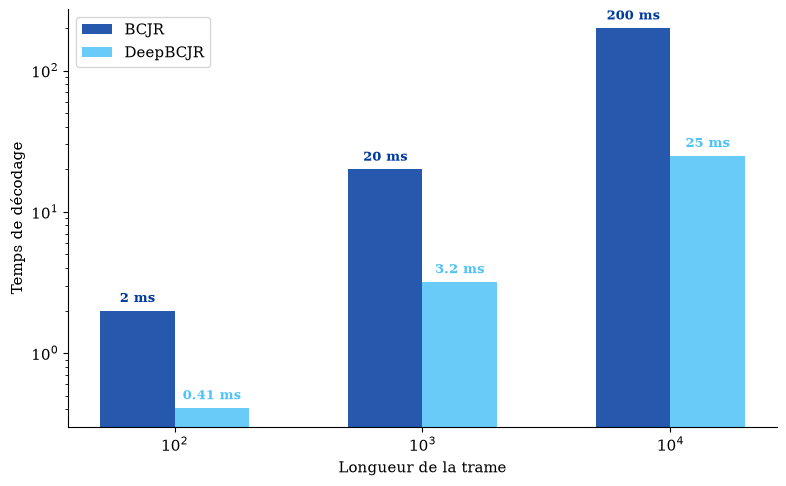

In [68]:
block_lengths = [100, 1000, 10000]
deepturbo =      [0.41, 3.2, 25]
classiqueturbo = [2, 20, 200]

x = np.arange(len(block_lengths))
w = 0.3

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - w/2, classiqueturbo, w, label='BCJR', color='#003B9F', alpha=0.85)
ax.bar(x + w/2, deepturbo, w, label='DeepBCJR', color='#4FC3F7', alpha=0.85)

for i in range(len(x)):
    ax.text(x[i] - w/2, classiqueturbo[i] * 1.15, f'{classiqueturbo[i]} ms', ha='center', fontsize=9, fontweight='bold', color='#003B9F')
    ax.text(x[i] + w/2, deepturbo[i] * 1.15, f'{deepturbo[i]} ms', ha='center', fontsize=9, fontweight='bold', color='#4FC3F7')


ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels([f'$10^{int(np.log10(bl))}$' for bl in block_lengths])
ax.set_ylabel('Temps de décodage')
ax.set_xlabel('Longueur de la trame')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
#plt.savefig('vitesse.png', dpi=300, bbox_inches='tight')
plt.show()

#### **7.2. Évolution du facteur de vitesse**

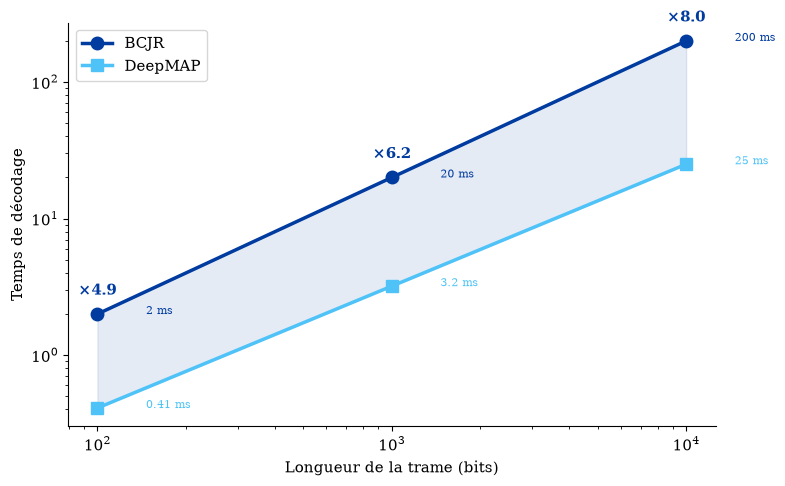

In [69]:
block_lengths = [100, 1000, 10000]
deepturbo =      [0.41, 3.2, 25]
classiqueturbo = [2, 20, 200]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(block_lengths, classiqueturbo, 'o-', color='#003B9F', label='BCJR', linewidth=2.5, markersize=9)
ax.plot(block_lengths, deepturbo, 's-', color='#4FC3F7', label='DeepMAP', linewidth=2.5, markersize=9)

ax.fill_between(block_lengths, deepturbo, classiqueturbo, alpha=0.1, color='#003B9F')

for i in range(len(block_lengths)):
    ratio = classiqueturbo[i] / deepturbo[i]
    ax.annotate(f'×{ratio:.1f}', xy=(block_lengths[i], classiqueturbo[i]), xytext=(0, 14), textcoords='offset points', fontsize=11, fontweight='bold', color='#003B9F', ha='center')
    ax.annotate(f'{classiqueturbo[i]} ms', xy=(block_lengths[i], classiqueturbo[i]), xytext=(35, 0), textcoords='offset points', fontsize=8, color='#003B9F', ha='left')
    ax.annotate(f'{deepturbo[i]} ms', xy=(block_lengths[i], deepturbo[i]), xytext=(35, 0), textcoords='offset points', fontsize=8, color='#4FC3F7', ha='left')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Longueur de la trame (bits)')
ax.set_ylabel('Temps de décodage')
ax.legend(loc='upper left')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
#plt.savefig('facteur.png', dpi=300, bbox_inches='tight')
plt.show()